# Лабораторна робота 2. Завдання 3–4 (AID, варіант 3)

* **Завдання 3** — попередньо навчена **ResNet18** (ImageNet), класифікаційний шар замінено на 30 класів,
  основа мережі **заморожена**, навчається лише новий класифікатор.
* **Завдання 4** — те саме навчання, але **з аугментацією** навчальної вибірки; порівняння з завданням 3.

**Умови порівняння** (з методички):
* однаковий поділ даних — поділ зафіксовано нижче (15 val + 20 test з кожного класу, відібрані так,
  щоб серед них не було дуже схожих зображень; решта — train);
* аугментація — **лише** для train;
* однакові початкові ваги класифікатора і однаковий бюджет навчання (епохи, оптимізатор, LR, scheduler, batch size,
  порядок батчів);
* модель (епоху) обираємо за **validation**, остаточні результати — на **test**.

Ноутбук розрахований на запуск на **Kaggle з GPU** (`kaggle kernels push -p steps3_4`), датасет підключено як input.
Локально теж запускається (шукає `data/AID`), але на CPU навчання повільне.

## 0. Налаштування

In [1]:
import os, json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms.v2 import functional as TF
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
IMG_SIZE = 224                 # стандартний вхід для моделей, навчених на ImageNet
BATCH_SIZE = 64
EPOCHS = 20                    # однаковий бюджет для exp3 та exp4
LR = 1e-3
WEIGHT_DECAY = 1e-4
BLUR_SIGMA = (0.5, 1.2)        # «легке» розмиття: sigma гаусового ядра 5×5
NUM_WORKERS = min(4, os.cpu_count())
MP_CONTEXT = 'fork' if NUM_WORKERS > 0 else None   # воркери бачать кеш зображень у RAM без копіювання

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
OUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
print('outputs ->', OUT_DIR)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

device: cuda Tesla T4
outputs -> /kaggle/working


## 1. Дані та поділ

Датасет шукаємо в `data/` (локально) або в `/kaggle/input` (на Kaggle).
Поділ val/test вбудовано в ноутбук як номери файлів (`<клас>_<номер>.jpg`) — він збігається з `artifacts/split.csv`
і з директоріями `data/AID_split/`, створеними скриптом `make_split.py`.

In [2]:
VAL_TEST = {   # клас: ([номери файлів val], [номери файлів test])
    'Airport': ([20, 22, 23, 54, 125, 154, 202, 236, 238, 244, 256, 294, 297, 306, 309],
               [1, 29, 38, 46, 47, 85, 91, 97, 190, 206, 223, 231, 234, 251, 262, 278, 311, 314, 329, 345]),
    'BareLand': ([57, 58, 73, 96, 98, 104, 112, 154, 181, 205, 232, 236, 245, 273, 303],
                [2, 5, 40, 60, 62, 63, 77, 109, 115, 120, 146, 163, 167, 187, 192, 217, 221, 231, 267, 282]),
    'BaseballField': ([3, 13, 14, 36, 74, 86, 98, 132, 135, 145, 149, 153, 180, 183, 197],
                     [10, 26, 40, 53, 55, 58, 80, 119, 129, 131, 147, 173, 175, 178, 187, 188, 198, 205, 211, 217]),
    'Beach': ([11, 28, 43, 93, 107, 126, 136, 180, 269, 274, 286, 293, 321, 341, 381],
             [3, 64, 72, 77, 128, 134, 142, 153, 161, 171, 175, 246, 275, 279, 280, 292, 310, 313, 316, 333]),
    'Bridge': ([64, 66, 90, 124, 135, 141, 161, 168, 207, 210, 211, 216, 225, 275, 350],
              [33, 35, 40, 49, 52, 55, 74, 139, 150, 151, 159, 181, 192, 198, 247, 256, 301, 338, 340, 352]),
    'Center': ([35, 47, 55, 62, 79, 83, 156, 158, 170, 171, 208, 222, 228, 239, 240],
              [11, 14, 21, 37, 53, 61, 103, 106, 164, 168, 174, 182, 202, 204, 214, 218, 223, 232, 235, 251]),
    'Church': ([26, 47, 49, 71, 80, 82, 97, 114, 117, 125, 160, 187, 203, 209, 233],
              [3, 7, 9, 20, 28, 51, 53, 58, 63, 70, 74, 78, 99, 151, 175, 197, 199, 234, 237, 240]),
    'Commercial': ([9, 29, 106, 116, 133, 168, 182, 211, 218, 231, 282, 287, 318, 349, 350],
                  [2, 21, 33, 87, 122, 124, 130, 132, 140, 162, 185, 201, 223, 235, 255, 273, 307, 322, 332, 342]),
    'DenseResidential': ([8, 19, 29, 41, 66, 88, 153, 172, 263, 265, 275, 318, 332, 365, 399],
                        [10, 46, 54, 57, 60, 63, 68, 76, 83, 100, 110, 111, 113, 188, 190, 197, 249, 259, 294, 335]),
    'Desert': ([12, 35, 71, 98, 126, 202, 223, 237, 243, 244, 270, 283, 290, 293, 299],
              [23, 44, 54, 64, 69, 73, 90, 121, 138, 144, 152, 185, 186, 231, 255, 256, 266, 279, 289, 292]),
    'Farmland': ([86, 114, 123, 188, 192, 194, 199, 213, 221, 228, 232, 271, 341, 352, 355],
                [3, 21, 43, 100, 155, 195, 201, 208, 215, 217, 220, 226, 236, 253, 270, 273, 290, 320, 329, 336]),
    'Forest': ([3, 22, 37, 40, 70, 75, 112, 114, 141, 149, 197, 198, 221, 224, 235],
              [1, 4, 10, 23, 26, 29, 56, 58, 87, 101, 130, 131, 137, 161, 163, 168, 172, 185, 200, 213]),
    'Industrial': ([19, 23, 55, 56, 117, 128, 131, 138, 145, 151, 232, 279, 293, 350, 376],
                  [11, 13, 24, 25, 32, 48, 62, 64, 92, 123, 130, 143, 178, 217, 225, 228, 303, 308, 309, 330]),
    'Meadow': ([3, 15, 30, 32, 102, 115, 116, 136, 154, 166, 204, 208, 210, 217, 231],
              [2, 27, 45, 46, 49, 93, 105, 119, 122, 126, 129, 147, 193, 197, 198, 211, 241, 251, 257, 273]),
    'MediumResidential': ([4, 6, 14, 19, 37, 67, 75, 116, 119, 125, 180, 182, 188, 238, 249],
                         [1, 3, 5, 8, 11, 13, 15, 22, 24, 29, 109, 114, 130, 163, 202, 205, 207, 210, 284, 289]),
    'Mountain': ([6, 12, 22, 29, 40, 50, 70, 91, 117, 132, 145, 175, 206, 239, 310],
                [11, 16, 20, 24, 51, 54, 98, 101, 119, 137, 142, 146, 154, 166, 185, 190, 218, 225, 237, 336]),
    'Park': ([3, 7, 32, 39, 82, 126, 127, 176, 192, 249, 256, 269, 284, 304, 322],
            [1, 2, 33, 54, 57, 83, 105, 112, 129, 168, 184, 201, 225, 228, 288, 289, 310, 311, 321, 345]),
    'Parking': ([2, 109, 117, 140, 144, 165, 215, 273, 282, 284, 287, 302, 336, 341, 377],
               [7, 21, 94, 98, 110, 148, 167, 169, 184, 204, 210, 214, 219, 230, 257, 275, 290, 345, 354, 386]),
    'Playground': ([6, 32, 65, 90, 109, 133, 151, 174, 214, 222, 250, 255, 283, 299, 356],
                  [25, 41, 43, 53, 72, 75, 111, 112, 116, 122, 178, 202, 224, 280, 296, 304, 321, 343, 349, 364]),
    'Pond': ([58, 69, 121, 165, 174, 181, 182, 186, 193, 200, 223, 276, 331, 392, 419],
            [13, 16, 30, 102, 105, 145, 160, 167, 180, 204, 211, 220, 231, 251, 280, 324, 371, 382, 396, 418]),
    'Port': ([3, 22, 30, 38, 51, 63, 64, 94, 137, 158, 161, 168, 205, 264, 292],
            [75, 79, 92, 99, 104, 173, 195, 200, 220, 231, 235, 237, 251, 269, 298, 303, 309, 334, 340, 375]),
    'RailwayStation': ([18, 29, 36, 39, 56, 91, 94, 143, 149, 150, 151, 174, 194, 242, 250],
                      [6, 25, 41, 43, 61, 63, 69, 75, 87, 96, 109, 114, 135, 141, 154, 161, 170, 217, 228, 240]),
    'Resort': ([67, 104, 123, 124, 134, 138, 175, 184, 201, 255, 273, 275, 279, 283, 285],
              [11, 14, 76, 91, 114, 130, 132, 162, 163, 178, 191, 200, 207, 220, 226, 228, 246, 249, 281, 287]),
    'River': ([33, 76, 111, 161, 240, 292, 303, 307, 324, 331, 334, 347, 349, 375, 386],
             [38, 44, 64, 86, 125, 156, 208, 212, 229, 244, 255, 259, 264, 298, 313, 327, 344, 360, 366, 389]),
    'School': ([6, 12, 69, 94, 114, 137, 160, 164, 168, 171, 187, 191, 222, 235, 246],
              [17, 18, 19, 39, 84, 96, 108, 130, 132, 146, 152, 205, 207, 224, 227, 284, 286, 287, 290, 299]),
    'SparseResidential': ([16, 19, 34, 52, 76, 81, 112, 113, 134, 152, 160, 178, 235, 278, 285],
                         [1, 23, 27, 44, 54, 58, 62, 69, 78, 91, 92, 125, 126, 136, 141, 145, 179, 228, 241, 289]),
    'Square': ([45, 53, 68, 106, 112, 115, 117, 179, 205, 209, 250, 312, 317, 321, 330],
              [13, 24, 46, 59, 90, 91, 148, 165, 187, 193, 196, 202, 212, 232, 271, 282, 284, 304, 314, 329]),
    'Stadium': ([5, 6, 60, 69, 97, 117, 121, 143, 176, 205, 228, 242, 262, 284, 289],
               [4, 9, 23, 26, 28, 29, 31, 58, 61, 132, 135, 141, 145, 180, 183, 190, 197, 226, 266, 276]),
    'StorageTanks': ([25, 41, 62, 67, 99, 172, 223, 256, 260, 282, 301, 321, 341, 347, 349],
                    [31, 34, 57, 69, 73, 105, 110, 141, 189, 204, 206, 216, 234, 245, 249, 317, 320, 351, 358, 359]),
    'Viaduct': ([27, 73, 112, 125, 126, 150, 190, 226, 241, 250, 299, 329, 339, 400, 416],
               [16, 32, 62, 90, 103, 123, 161, 168, 183, 191, 213, 214, 240, 265, 266, 269, 343, 348, 386, 397]),
}

In [3]:
def find_aid_root():
    # Папка, в якій лежать усі 30 папок-класів (беремо оригінальний AID, а не копії поділу)
    for base in (Path('data'), Path('../data'), Path('/kaggle/input')):
        if not base.exists():
            continue
        for p in sorted(base.rglob('Airport')):
            if p.is_dir() and all((p.parent / c).is_dir() for c in VAL_TEST) and 'AID_split' not in p.parts:
                return p.parent
    raise FileNotFoundError('Датасет AID не знайдено: завантажте його в data/ або підключіть як Kaggle input')


DATA_DIR = find_aid_root()
classes = sorted(VAL_TEST)
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)

records = []
for c in classes:
    val_ids, test_ids = map(set, VAL_TEST[c])
    for f in sorted((DATA_DIR / c).glob('*.jpg')):
        n = int(f.stem.rsplit('_', 1)[1])
        split = 'val' if n in val_ids else 'test' if n in test_ids else 'train'
        records.append((str(f), c, class_to_idx[c], split))
df = pd.DataFrame(records, columns=['path', 'class', 'label', 'split'])

counts = pd.crosstab(df['class'], df['split'])
assert (counts['val'] == 15).all() and (counts['test'] == 20).all(), 'поділ не збігається з файлами датасету'
print('Папка з класами:', DATA_DIR)
print(f'Класів: {NUM_CLASSES}, зображень: {len(df)}', df['split'].value_counts().to_dict())

Папка з класами: /kaggle/input/datasets/jiayuanchengala/aid-scene-classification-datasets/AID
Класів: 30, зображень: 10000 {'train': 8950, 'test': 600, 'val': 450}


### Кешування зображень у пам'яті

Оригінали 600×600; декодувати JPEG на кожній епосі — вузьке місце. Тому **один раз** зменшуємо всі зображення
до 224×224 і тримаємо їх у RAM як `uint8` (~1.5 ГБ). Аугментація застосовується до цих тензорів у `__getitem__`,
нормалізація — уже на GPU.

In [4]:
class PathDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            im.draft('RGB', (IMG_SIZE, IMG_SIZE))   # JPEG декодується одразу в 300×300 — швидше
            im = im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1)   # HWC -> CHW, uint8


IMAGES = torch.empty((len(df), 3, IMG_SIZE, IMG_SIZE), dtype=torch.uint8)
LABELS = torch.tensor(df['label'].values, dtype=torch.long)
pos = 0
for batch in tqdm(DataLoader(PathDataset(df['path']), batch_size=128, num_workers=NUM_WORKERS,
                             multiprocessing_context=MP_CONTEXT), desc='Кешування'):
    IMAGES[pos:pos + len(batch)] = batch
    pos += len(batch)

idx = {s: np.where(df['split'] == s)[0] for s in ('train', 'val', 'test')}
print(IMAGES.shape, f'{IMAGES.numel() / 1024**3:.2f} GB')

Кешування:   0%|          | 0/79 [00:00<?, ?it/s]

torch.Size([10000, 3, 224, 224]) 1.40 GB


## 2. Аугментація

У `__getitem__` для кожного навчального зображення **випадково обирається одна** з трьох аугментацій:

| Аугментація | Параметри | Чому підходить для AID |
|---|---|---|
| поворот на 90° | k ∈ {1, 2, 3} (90°, 180°, 270°) | знімки зроблені згори — у сцени немає «верху» |
| віддзеркалення | горизонтальне або вертикальне | так само: дзеркальна сцена правдоподібна |
| легке розмиття | гаусове ядро 5×5, σ ∈ [0.5, 1.2] | імітує різну роздільність сенсорів Google Earth |

Кольорові аугментації свідомо не використовуємо: колір — важлива ознака багатьох класів (ліс, пустеля, пляж, ставок).
Вибір аугментації і її параметрів робиться через `torch` RNG — DataLoader сідує його в кожному воркері від свого
генератора, тому послідовність аугментацій відтворювана.

In [5]:
AUG_OPS = ('rot90', 'flip', 'blur')


def augment(x, op):
    # x: uint8-тензор 3×H×W
    if op == 'rot90':
        return torch.rot90(x, int(torch.randint(1, 4, ())), dims=(1, 2))
    if op == 'flip':
        return x.flip(2) if torch.rand(()) < 0.5 else x.flip(1)   # горизонтальне / вертикальне
    if op == 'blur':
        sigma = float(torch.empty(()).uniform_(*BLUR_SIGMA))
        return TF.gaussian_blur(x, kernel_size=[5, 5], sigma=[sigma, sigma])
    raise ValueError(op)


class AIDDataset(Dataset):
    def __init__(self, indices, augment=False):
        self.indices = np.asarray(indices)
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x = IMAGES[j]
        if self.augment:
            x = augment(x, AUG_OPS[int(torch.randint(len(AUG_OPS), ()))])
        return x, LABELS[j]


def make_loader(indices, augment=False, shuffle=False, seed=SEED):
    # Окремий генератор з тим самим seed -> однаковий порядок батчів (і аугментацій) у парних експериментах
    return DataLoader(AIDDataset(indices, augment), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=NUM_WORKERS,
                      multiprocessing_context=MP_CONTEXT, persistent_workers=NUM_WORKERS > 0,
                      pin_memory=device.type == 'cuda')


train_loader = make_loader(idx['train'], shuffle=True)
train_loader_aug = make_loader(idx['train'], augment=True, shuffle=True)
train_eval_loader = make_loader(idx['train'])          # train без аугментації — для оцінки перенавчання
val_loader = make_loader(idx['val'])
test_loader = make_loader(idx['test'])

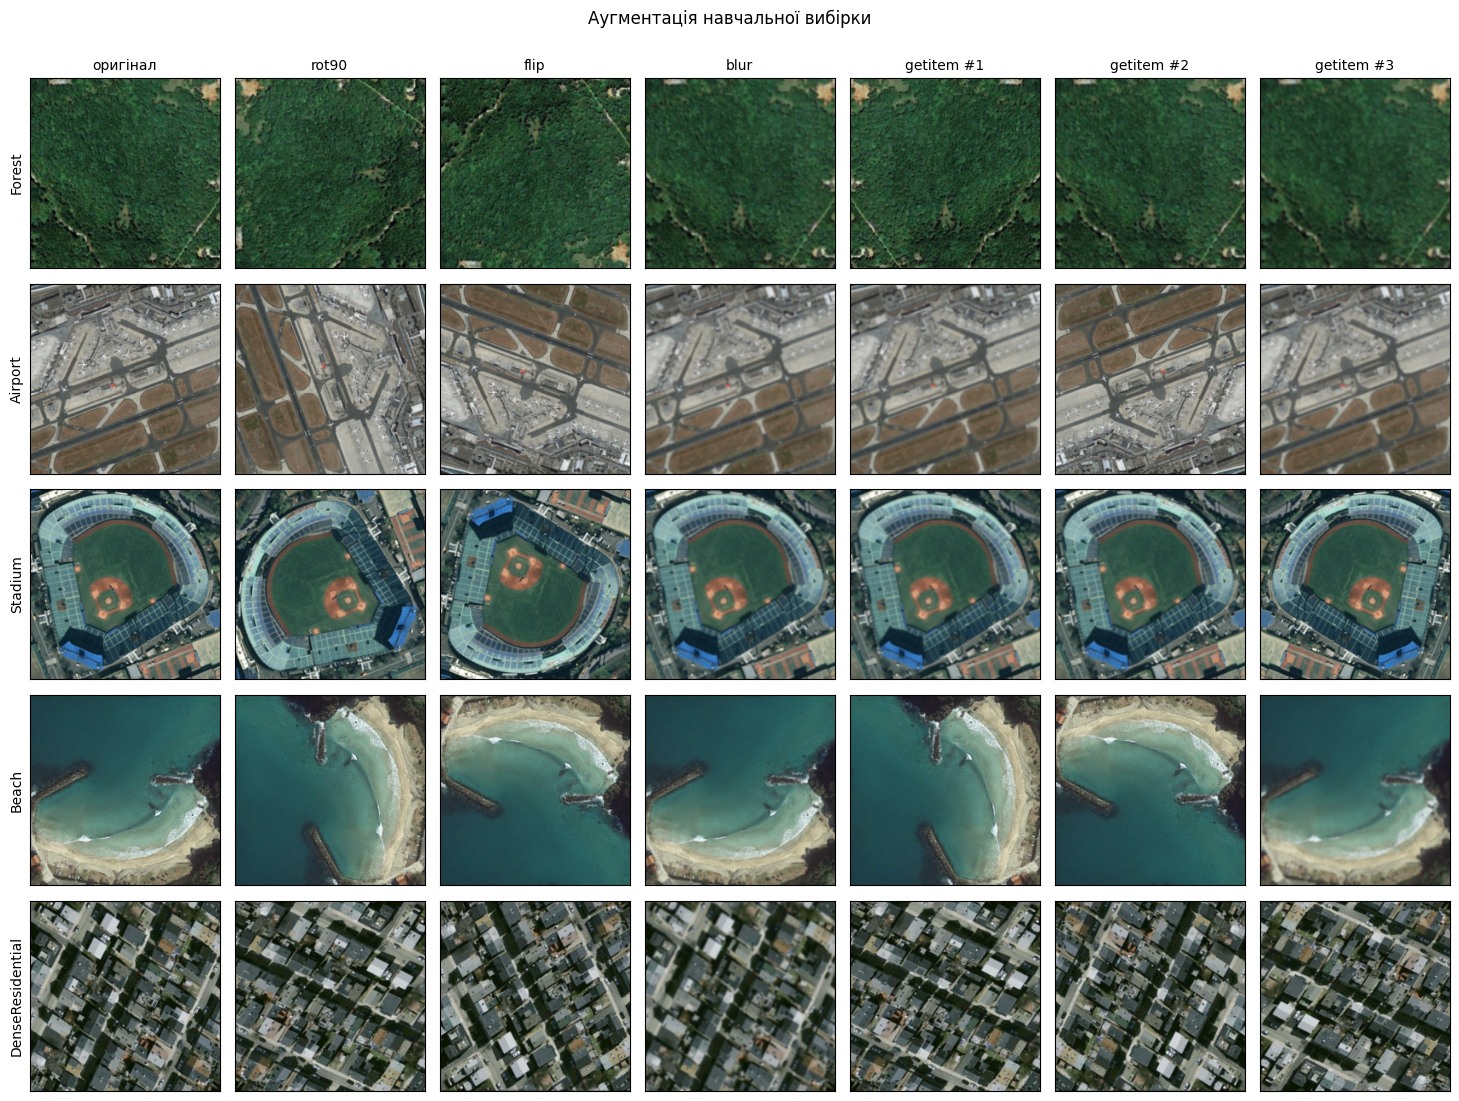

In [6]:
# Приклади аугментованих зображень: оригінал, кожна аугментація окремо та 3 випадкові виклики __getitem__
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
examples = [rng.choice(idx['train'][df['class'].values[idx['train']] == c])
            for c in ('Forest', 'Airport', 'Stadium', 'Beach', 'DenseResidential')]
aug_ds = AIDDataset(examples, augment=True)

cols = ['оригінал', 'rot90', 'flip', 'blur', 'getitem #1', 'getitem #2', 'getitem #3']
fig, axes = plt.subplots(len(examples), len(cols), figsize=(2.1 * len(cols), 2.2 * len(examples)))
for r, j in enumerate(examples):
    imgs = [IMAGES[j]] + [augment(IMAGES[j], op) for op in AUG_OPS] + [aug_ds[r][0] for _ in range(3)]
    for c, (ax, im) in enumerate(zip(axes[r], imgs)):
        ax.imshow(im.permute(1, 2, 0).numpy())
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(cols[c], fontsize=10)
    axes[r, 0].set_ylabel(df['class'][j], fontsize=10)
plt.suptitle('Аугментація навчальної вибірки', y=1.0)
plt.tight_layout()
plt.show()

## 3. Модель і цикл навчання

ResNet18 з вагами ImageNet; `fc` (512 → 1000) замінюємо на `Linear(512 → 30)`. Заморожуємо всі шари, крім `fc`.
Замороженим BatchNorm-шарам залишаємо режим `eval()` — інакше вони оновлювали б свої статистики під час навчання,
хоча ваги основи «заморожені».

Початкові ваги нового `fc` генеруються **один раз** і зберігаються — exp3 і exp4 стартують з однакових ваг.

In [7]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255


def to_input(x):
    return (x.to(device, non_blocking=True).float() - IMAGENET_MEAN) / IMAGENET_STD


def build_resnet18():
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model


def freeze_backbone(model, trainable=('fc',)):
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith(trainable)


def set_train_mode(model):
    # train() лише для шарів, що навчаються; заморожені BatchNorm лишаються в eval()
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


set_seed()
init_fc = build_resnet18().fc.state_dict()
torch.save(init_fc, OUT_DIR / 'init_fc.pt')

m = build_resnet18()
freeze_backbone(m)
print(f'Усього параметрів: {count_params(m):,}; навчається: {count_params(m, trainable_only=True):,}')
del m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]


Усього параметрів: 11,191,902; навчається: 15,390


In [8]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits.append(model(to_input(x)).float().cpu())
        labels.append(y)
    return torch.cat(logits), torch.cat(labels)


def metrics(logits, labels):
    pred = logits.argmax(1).numpy()
    return {'loss': F.cross_entropy(logits, labels).item(),
            'acc': accuracy_score(labels, pred),
            'f1': f1_score(labels, pred, average='macro')}


def fit(model, train_loader, name, epochs=EPOCHS, lr=LR):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    hist = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1')}
    best_acc, best_state, best_epoch = -1, None, 0
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        set_train_mode(model)
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = to_input(x), y.to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = F.cross_entropy(logits, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            tot_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
        scheduler.step()

        val = metrics(*predict(model, val_loader))
        for k, v in (('train_loss', tot_loss / n), ('train_acc', correct / n),
                     ('val_loss', val['loss']), ('val_acc', val['acc']), ('val_f1', val['f1'])):
            hist[k].append(v)
        if val['acc'] > best_acc:   # вибір епохи — лише за validation
            best_acc, best_epoch = val['acc'], epoch
            best_state = copy.deepcopy(model.state_dict())
        print(f'[{name}] epoch {epoch:2d}/{epochs}  train loss {tot_loss / n:.4f} acc {correct / n:.4f} | '
              f'val loss {val["loss"]:.4f} acc {val["acc"]:.4f} f1 {val["f1"]:.4f}  ({time.time() - t0:.0f} s)')

    model.load_state_dict(best_state)
    torch.save(best_state, OUT_DIR / f'{name}.pt')
    hist.update(best_epoch=best_epoch, train_time=time.time() - t0)
    print(f'[{name}] найкраща епоха за val acc: {best_epoch} ({best_acc:.4f}), ваги -> {OUT_DIR / name}.pt')
    return hist


results, histories, test_preds = {}, {}, {}


def evaluate_model(model, name, hist):
    row = {'trainable_params': count_params(model, trainable_only=True), 'best_epoch': hist['best_epoch'],
           'train_time_s': round(hist['train_time'])}
    for split, loader in (('train', train_eval_loader), ('val', val_loader), ('test', test_loader)):
        logits, labels = predict(model, loader)
        m = metrics(logits, labels)
        row[f'{split}_acc'], row[f'{split}_f1'] = m['acc'], m['f1']
        if split == 'test':
            test_preds[name] = logits.argmax(1).numpy()
    row['train-val gap'] = row['train_acc'] - row['val_acc']
    results[name], histories[name] = row, hist
    return pd.Series(row).round(4)

## 4. Завдання 3: заморожена основа, без аугментації

In [9]:
set_seed()
model_fe = build_resnet18()
model_fe.fc.load_state_dict(init_fc)
freeze_backbone(model_fe)
model_fe = model_fe.to(device)

hist_fe = fit(model_fe, train_loader, 'exp3_frozen')
evaluate_model(model_fe, 'exp3_frozen', hist_fe)

[exp3_frozen] epoch  1/20  train loss 1.5696 acc 0.6682 | val loss 1.2339 acc 0.6933 f1 0.6944  (6 s)
[exp3_frozen] epoch  2/20  train loss 0.6217 acc 0.8657 | val loss 0.9778 acc 0.7222 f1 0.7211  (11 s)
[exp3_frozen] epoch  3/20  train loss 0.4547 acc 0.8942 | val loss 0.8924 acc 0.7600 f1 0.7589  (15 s)
[exp3_frozen] epoch  4/20  train loss 0.3746 acc 0.9107 | val loss 0.8470 acc 0.7578 f1 0.7557  (19 s)
[exp3_frozen] epoch  5/20  train loss 0.3302 acc 0.9181 | val loss 0.8065 acc 0.7622 f1 0.7600  (24 s)
[exp3_frozen] epoch  6/20  train loss 0.2974 acc 0.9250 | val loss 0.7888 acc 0.7644 f1 0.7635  (28 s)
[exp3_frozen] epoch  7/20  train loss 0.2701 acc 0.9318 | val loss 0.7562 acc 0.7733 f1 0.7726  (32 s)
[exp3_frozen] epoch  8/20  train loss 0.2491 acc 0.9377 | val loss 0.7615 acc 0.7756 f1 0.7756  (37 s)
[exp3_frozen] epoch  9/20  train loss 0.2337 acc 0.9428 | val loss 0.7537 acc 0.7756 f1 0.7752  (42 s)
[exp3_frozen] epoch 10/20  train loss 0.2212 acc 0.9460 | val loss 0.7339 

trainable_params    15390.0000
best_epoch             14.0000
train_time_s           93.0000
train_acc               0.9566
train_f1                0.9544
val_acc                 0.8000
val_f1                  0.7992
test_acc                0.8050
test_f1                 0.8059
train-val gap           0.1566
dtype: float64

## 5. Завдання 4: заморожена основа + аугментація

Відрізняється від exp3 **лише** навчальним DataLoader (`train_loader_aug`): ті самі початкові ваги `fc`,
епохи, оптимізатор, LR, scheduler і порядок батчів.

In [10]:
set_seed()
model_aug = build_resnet18()
model_aug.fc.load_state_dict(init_fc)
freeze_backbone(model_aug)
model_aug = model_aug.to(device)

hist_aug = fit(model_aug, train_loader_aug, 'exp4_frozen_aug')
evaluate_model(model_aug, 'exp4_frozen_aug', hist_aug)

[exp4_frozen_aug] epoch  1/20  train loss 1.6438 acc 0.6423 | val loss 1.2305 acc 0.6933 f1 0.6939  (5 s)
[exp4_frozen_aug] epoch  2/20  train loss 0.6895 acc 0.8524 | val loss 0.9747 acc 0.7289 f1 0.7261  (10 s)
[exp4_frozen_aug] epoch  3/20  train loss 0.5243 acc 0.8718 | val loss 0.8840 acc 0.7622 f1 0.7615  (15 s)
[exp4_frozen_aug] epoch  4/20  train loss 0.4449 acc 0.8848 | val loss 0.8408 acc 0.7622 f1 0.7587  (20 s)
[exp4_frozen_aug] epoch  5/20  train loss 0.4065 acc 0.8920 | val loss 0.8112 acc 0.7778 f1 0.7744  (24 s)
[exp4_frozen_aug] epoch  6/20  train loss 0.3669 acc 0.8999 | val loss 0.7932 acc 0.7600 f1 0.7589  (29 s)
[exp4_frozen_aug] epoch  7/20  train loss 0.3446 acc 0.9057 | val loss 0.7521 acc 0.7911 f1 0.7892  (34 s)
[exp4_frozen_aug] epoch  8/20  train loss 0.3225 acc 0.9160 | val loss 0.7535 acc 0.7733 f1 0.7724  (39 s)
[exp4_frozen_aug] epoch  9/20  train loss 0.3091 acc 0.9162 | val loss 0.7527 acc 0.7822 f1 0.7809  (44 s)
[exp4_frozen_aug] epoch 10/20  train l

trainable_params    15390.0000
best_epoch             20.0000
train_time_s           98.0000
train_acc               0.9399
train_f1                0.9366
val_acc                 0.8000
val_f1                  0.7979
test_acc                0.7900
test_f1                 0.7886
train-val gap           0.1399
dtype: float64

## 6. Порівняння exp3 і exp4

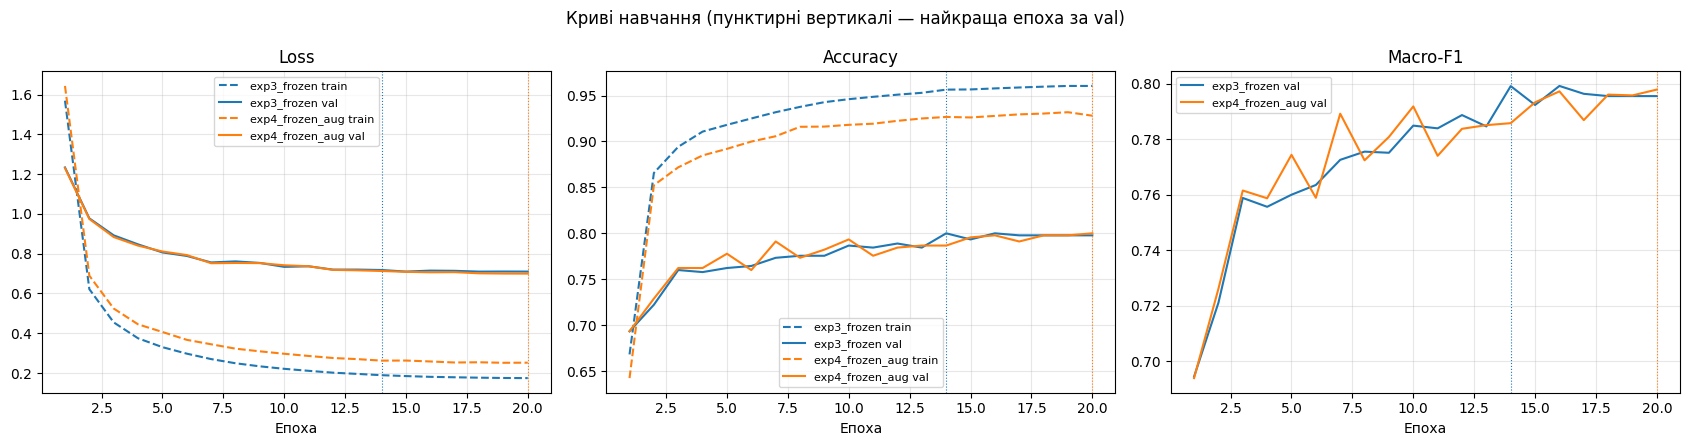

,trainable_params,best_epoch,train_time_s,train_acc,train_f1,val_acc,val_f1,test_acc,test_f1,train-val gap
exp3_frozen,15390.0,14.0,93.0,0.9566,0.9544,0.8,0.7992,0.805,0.8059,0.1566
exp4_frozen_aug,15390.0,20.0,98.0,0.9399,0.9366,0.8,0.7979,0.790,0.7886,0.1399


In [11]:
def plot_histories(hists):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for (name, h), color in zip(hists.items(), ('tab:blue', 'tab:orange', 'tab:green')):
        ep = range(1, len(h['train_loss']) + 1)
        axes[0].plot(ep, h['train_loss'], color=color, ls='--', label=f'{name} train')
        axes[0].plot(ep, h['val_loss'], color=color, label=f'{name} val')
        axes[1].plot(ep, h['train_acc'], color=color, ls='--', label=f'{name} train')
        axes[1].plot(ep, h['val_acc'], color=color, label=f'{name} val')
        axes[2].plot(ep, h['val_f1'], color=color, label=f'{name} val')
        for ax in axes:
            ax.axvline(h['best_epoch'], color=color, lw=0.8, ls=':')
    for ax, t in zip(axes, ('Loss', 'Accuracy', 'Macro-F1')):
        ax.set_title(t); ax.set_xlabel('Епоха'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.suptitle('Криві навчання (пунктирні вертикалі — найкраща епоха за val)')
    plt.tight_layout()
    plt.show()


plot_histories(histories)

summary = pd.DataFrame(results).T
summary.to_csv(OUT_DIR / 'results_steps3_4.csv')
summary.round(4)

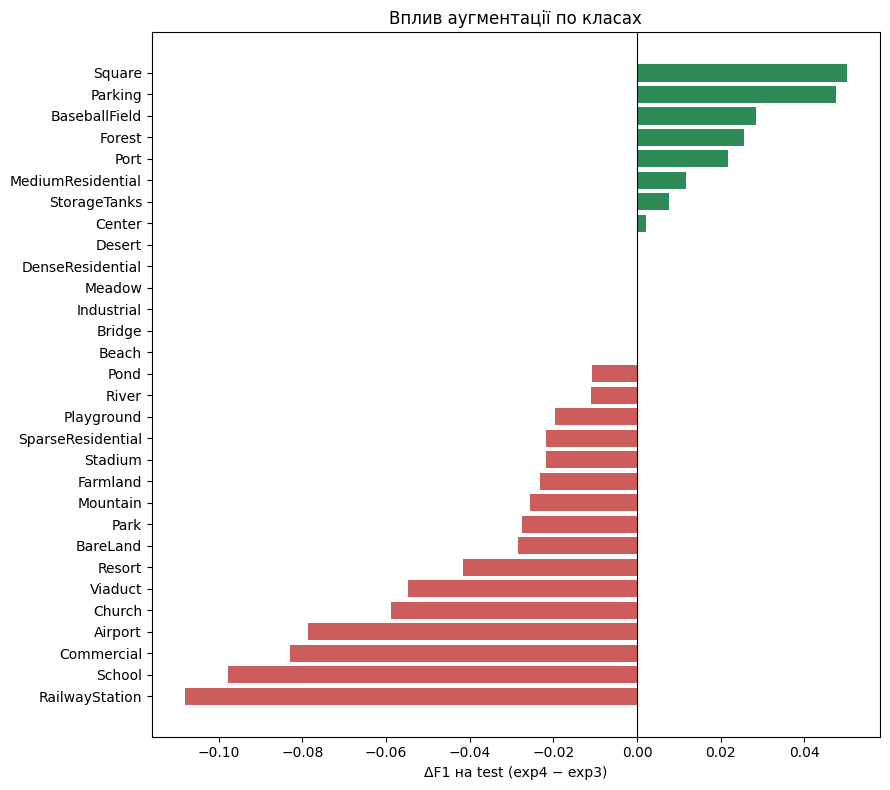

Виправлено помилок exp3: 11, нових помилок у exp4: 20 (з 600 тестових)


,exp3_frozen,exp4_frozen_aug,delta
RailwayStation,0.757,0.649,-0.108
School,0.485,0.387,-0.098
Commercial,0.683,0.600,-0.083
Airport,0.732,0.653,-0.079
Church,0.647,0.588,-0.059
Viaduct,0.905,0.850,-0.055
Resort,0.531,0.489,-0.042
BareLand,0.923,0.895,-0.028
Park,0.708,0.681,-0.027
Mountain,1.000,0.974,-0.026


In [12]:
# Які класи виграли / програли від аугментації (test macro-F1 по класах)
y_test = LABELS[idx['test']].numpy()
f1_pc = pd.DataFrame({name: f1_score(y_test, p, average=None, labels=range(NUM_CLASSES))
                      for name, p in test_preds.items()}, index=classes)
f1_pc['delta'] = f1_pc['exp4_frozen_aug'] - f1_pc['exp3_frozen']
f1_pc = f1_pc.sort_values('delta')

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(f1_pc.index, f1_pc['delta'], color=np.where(f1_pc['delta'] >= 0, 'seagreen', 'indianred'))
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('ΔF1 на test (exp4 − exp3)')
ax.set_title('Вплив аугментації по класах')
plt.tight_layout()
plt.show()

fixed = ((test_preds['exp3_frozen'] != y_test) & (test_preds['exp4_frozen_aug'] == y_test)).sum()
broken = ((test_preds['exp3_frozen'] == y_test) & (test_preds['exp4_frozen_aug'] != y_test)).sum()
print(f'Виправлено помилок exp3: {fixed}, нових помилок у exp4: {broken} (з {len(y_test)} тестових)')

# Зберігаємо все, що знадобиться в наступних завданнях (5, 7–9)
np.savez(OUT_DIR / 'test_preds_steps3_4.npz', y_test=y_test, test_idx=idx['test'], **test_preds)
json.dump(histories, open(OUT_DIR / 'histories_steps3_4.json', 'w'))
f1_pc.round(3)

## 7. Висновки

_(заповнити після запуску, спираючись на таблицю та графіки вище)_

**Завдання 3.** Навчається лише `fc` (~15 тис. з 11.2 млн параметрів), тому модель — фактично лінійний класифікатор
над ознаками ImageNet. Вказати val/test accuracy і macro-F1; на якій епосі досягнуто найкращого val.

**Завдання 4 — вплив аугментації.**
* Чи зросли val/test accuracy і macro-F1 порівняно з exp3, на скільки.
* Train loss з аугментацією зазвичай вищий, бо навчальні приклади «складніші» — це нормально.
* Які класи виграли найбільше (графік ΔF1), скільки помилок виправлено і скільки з'явилося нових.
* Val — лише 450 зображень (15 на клас), тож одна помилка = 0.22 п.п. accuracy; різниця < ~1 п.п. може бути шумом.

**Ознаки перенавчання.** Порівняти `train-val gap` (accuracy на чистому train мінус val) для exp3 і exp4,
а також хід val loss: якщо val loss після певної епохи росте, поки train loss падає — це перенавчання.
Із замороженою основою модель має мало параметрів, тож сильного перенавчання не очікуємо; аугментація має
зменшити розрив train–val.